# Contact timing and stop-save acceptance

This notebook evaluates whether the delay of contact(gap between `pricing_effective_date` and `earlist_contact_date`) is associated with the Saved rate among contacted Regular Users, separately by Treatment. 
The exact day gap is retained for modeling; weekly groups are used for readable descriptive charts.

This is a retention-based acceptance proxy rather than a directly recorded acceptance event. The analysis is descriptive: contact timing is chosen by the user and is not randomized.

In [1]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from google.cloud import bigquery

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:,.3f}".format)

PROJECT_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").exists()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.eda_helpers import ID_COL, TREATMENT_COLORS

In [2]:
PROJECT_ID = "gannett-datascience"
USAGE_TABLE = "gannett-datascience.test_results_zone.ss_test_P3_usages_features"
TREATMENT_ORDER = ["Control", "Midpoint", "Tiered"]
PRIMARY_MIN_GAP = 0
SPLINE_KNOTS = np.array([0, 7, 30, 60, 90], dtype=float)
PREDICTION_DAYS = [0, 7, 14, 30, 60, 90]
BOOTSTRAP_ITERATIONS = 1_000

OUTPUT_ROOT = PROJECT_ROOT / "src" / "notebooks"
CHART_DIR = OUTPUT_ROOT / "charts" / "contact_timing_acceptance"
TABLE_DIR = OUTPUT_ROOT / "tables" / "contact_timing_acceptance"
CHART_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load contacted Regular Users

Regular contacted users are neither Repeat Restarters nor Repeat Stop-Saves. Load both mature and immature users to show maturity bias; the primary contact timing analysis uses mature users only.

In [ ]:
query = f"""
SELECT
  id_subscrip,
  inference_date,
  pricing_effective_date,
  earlist_contact_date,
  Treatment,
  cohort,
  src_risk_tier,
  contact_channels,
  contact_timing,
  pricegroup_order,
  is_two_payment_cycle_ago,
  churn_code,
  DATE_DIFF(earlist_contact_date, pricing_effective_date, DAY) AS gap_days
FROM `{USAGE_TABLE}`
WHERE contact_channels != 'No Action yet'
  AND Repeat_Restarts = 'not repeat restarts'
  AND Repeat_StopSaves = 'not repeate stop-saves'
  AND churn_code IN (0, 1)
"""

client = bigquery.Client(project=PROJECT_ID)
df = client.query(query).to_dataframe(create_bqstorage_client=False)
df["accepted"] = df["churn_code"].eq(0).astype(int)
df["pricing_effective_month"] = (
    pd.to_datetime(df["pricing_effective_date"]).dt.to_period("M").astype(str)
)

mature = df["is_two_payment_cycle_ago"].eq(1)
primary = df.loc[mature & df["gap_days"].ge(PRIMARY_MIN_GAP)].copy()
before_pricing = df.loc[mature & df["gap_days"].lt(0)].copy()
print(
    f"Loaded {len(df):,} contacted Regular Users: "
    f"{len(primary):,} mature On/After Pricing and "
    f"{len(before_pricing):,} mature Before Pricing."
)

/Users/YKang1/PycharmProjects/stop_save_pChurn/.venv/lib/python3.13/site-packages/google/auth/_default.py:113: UserWarning: Your application has authenticated using end user credentials from Google Cloud SDK without a quota project. You might receive a "quota exceeded" or "API not enabled" error. See the following page for troubleshooting: https://cloud.google.com/docs/authentication/adc-troubleshooting/user-creds. 
  warnings.warn(_CLOUD_SDK_CREDENTIALS_WARNING)


Loaded 12,475 contacted Regular Users: 5,100 mature On/After Pricing and 4,531 mature Before Pricing.


## 2. Population, maturity, and gap diagnostics

Recent cohorts have less time to reveal a stop and also cannot have long post-effective contact gaps. The maturity comparison below documents this censoring risk and supports using `is_two_payment_cycle_ago = 1` for the primary analysis.

In [4]:
def wilson_interval(successes, total, z=1.96):
    successes = np.asarray(successes, dtype=float)
    total = np.asarray(total, dtype=float)
    proportion = np.divide(successes, total, out=np.zeros_like(successes), where=total > 0)
    denominator = 1 + z**2 / total
    center = (proportion + z**2 / (2 * total)) / denominator
    spread = (
        z
        * np.sqrt(proportion * (1 - proportion) / total + z**2 / (4 * total**2))
        / denominator
    )
    return center - spread, center + spread


def summarize_acceptance(data, group_fields):
    summary = (
        data.groupby(group_fields, observed=True, dropna=False)
        .agg(
            users=(ID_COL, "nunique"),
            accepted=("accepted", "sum"),
            median_gap_days=("gap_days", "median"),
        )
        .reset_index()
    )
    summary["voluntary_stopped"] = summary["users"] - summary["accepted"]
    summary["acceptance_rate"] = summary["accepted"] / summary["users"]
    lower, upper = wilson_interval(summary["accepted"], summary["users"])
    summary["ci_lower"] = lower
    summary["ci_upper"] = upper
    return summary


on_after = df.loc[df["gap_days"].ge(0)].copy()
maturity_summary = summarize_acceptance(
    on_after, ["Treatment", "is_two_payment_cycle_ago"]
)
maturity_summary["maturity"] = maturity_summary["is_two_payment_cycle_ago"].map(
    {0: "Immature", 1: "Mature"}
)
maturity_summary.to_csv(TABLE_DIR / "maturity_sensitivity.csv", index=False)

gap_distribution = (
    primary.groupby("Treatment", observed=True)["gap_days"]
    .agg(
        users="size",
        minimum="min",
        p25=lambda x: x.quantile(0.25),
        median="median",
        p75=lambda x: x.quantile(0.75),
        p90=lambda x: x.quantile(0.90),
        p95=lambda x: x.quantile(0.95),
        maximum="max",
    )
    .reindex(TREATMENT_ORDER)
    .reset_index()
)
gap_distribution.to_csv(TABLE_DIR / "mature_gap_distribution.csv", index=False)
display(maturity_summary, gap_distribution)

,Treatment,is_two_payment_cycle_ago,users,accepted,median_gap_days,voluntary_stopped,acceptance_rate,ci_lower,ci_upper,maturity
0,Control,0,346,197,2.000,149,0.569,0.517,0.620,Immature
1,Control,1,2053,789,29.000,1264,0.384,0.364,0.406,Mature
2,Midpoint,0,386,142,3.000,244,0.368,0.321,0.417,Immature
3,Midpoint,1,2113,441,25.000,1672,0.209,0.192,0.227,Mature
4,Tiered,0,186,49,3.000,137,0.263,0.205,0.331,Immature
5,Tiered,1,934,163,26.500,771,0.175,0.152,0.200,Mature


,Treatment,users,minimum,p25,median,p75,p90,p95,maximum
0,Control,2053,0,6,29.000,59,88,104.400,181
1,Midpoint,2113,0,5,25.000,51,84,98.000,181
2,Tiered,934,0,5,26.500,49,74,92.000,141


## 3. Weekly descriptive acceptance rates

The exact day gap remains unchanged in the source data. For presentation, same-day contacts are separated, subsequent contacts use common seven-day intervals, and the sparse tail is pooled at 92+ days. Each point is the Saved share in that Treatment/bin; vertical lines are 95% Wilson intervals. Hollow points have fewer than 30 users and should be interpreted cautiously.

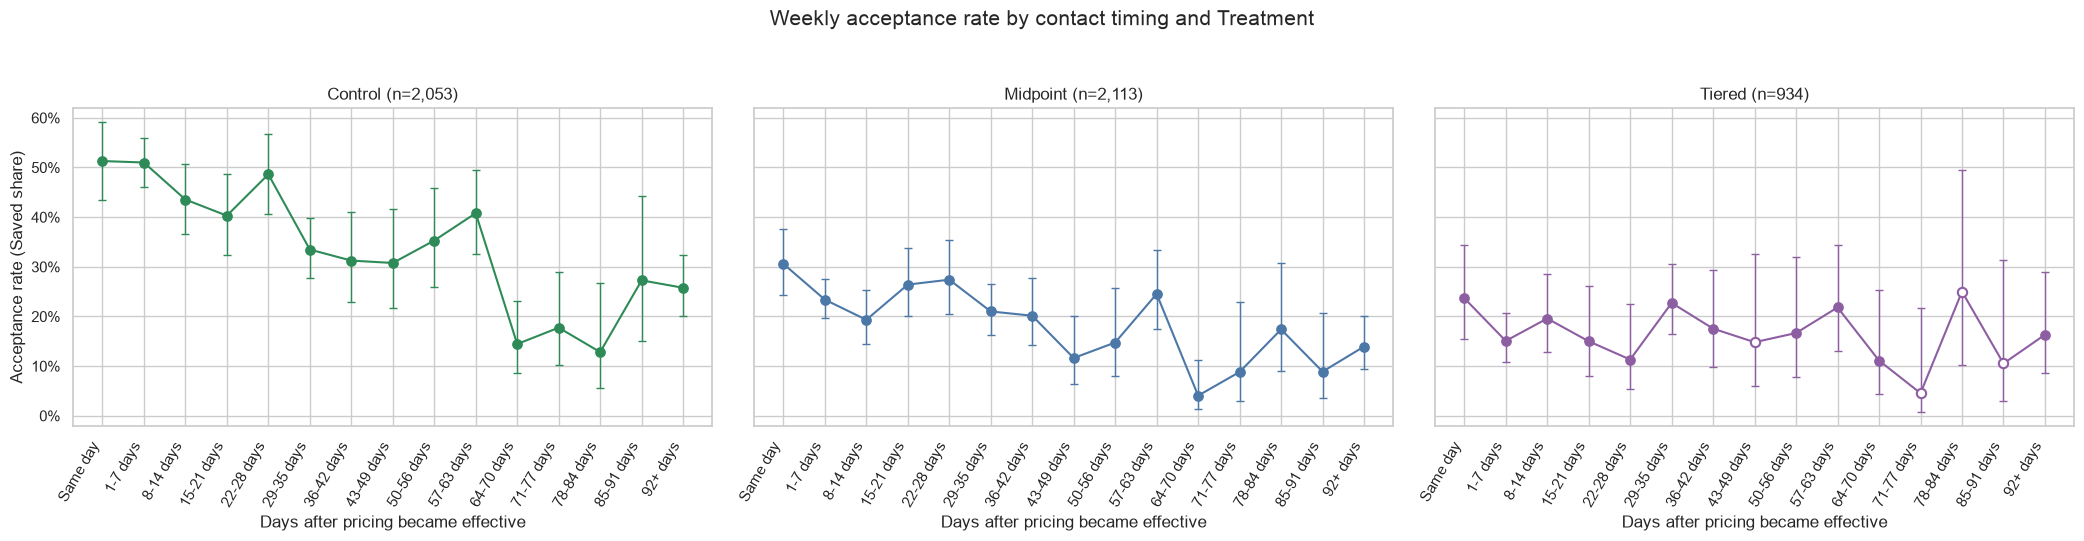

,Treatment,timing_bin,users,accepted,median_gap_days,voluntary_stopped,acceptance_rate,ci_lower,ci_upper
0,Control,Same day,154,79,0.000,75,0.513,0.435,0.591
1,Control,1-7 days,398,203,3.000,195,0.510,0.461,0.559
2,Control,8-14 days,186,81,11.000,105,0.435,0.366,0.507
3,Control,15-21 days,134,54,18.000,80,0.403,0.324,0.488
4,Control,22-28 days,146,71,25.000,75,0.486,0.407,0.567
5,Control,29-35 days,233,78,31.000,155,0.335,0.277,0.398
6,Control,36-42 days,96,30,39.000,66,0.312,0.229,0.411
7,Control,43-49 days,78,24,45.000,54,0.308,0.216,0.417
8,Control,50-56 days,85,30,53.000,55,0.353,0.260,0.459
9,Control,57-63 days,125,51,61.000,74,0.408,0.326,0.496


In [5]:
WEEKLY_BIN_ORDER = (
    ["Same day"]
    + [f"{start}-{start + 6} days" for start in range(1, 92, 7)]
    + ["92+ days"]
)


def weekly_gap_label(days):
    days = int(days)
    if days == 0:
        return "Same day"
    if days >= 92:
        return "92+ days"
    start = ((days - 1) // 7) * 7 + 1
    return f"{start}-{start + 6} days"


primary["timing_bin"] = pd.Categorical(
    primary["gap_days"].map(weekly_gap_label),
    categories=WEEKLY_BIN_ORDER,
    ordered=True,
)
weekly_acceptance = summarize_acceptance(primary, ["Treatment", "timing_bin"])
weekly_acceptance.to_csv(TABLE_DIR / "weekly_acceptance_by_treatment.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(21, 5.5), sharey=True)
bin_positions = {label: index for index, label in enumerate(WEEKLY_BIN_ORDER)}
for ax, treatment in zip(axes, TREATMENT_ORDER):
    plot_data = weekly_acceptance.loc[weekly_acceptance["Treatment"].eq(treatment)].copy()
    x = plot_data["timing_bin"].astype("string").map(bin_positions).to_numpy()
    y = plot_data["acceptance_rate"].to_numpy()
    color = TREATMENT_COLORS[treatment]
    ax.plot(x, y, color=color, linewidth=1.5)
    ax.errorbar(
        x, y,
        yerr=[y - plot_data["ci_lower"], plot_data["ci_upper"] - y],
        fmt="none", ecolor=color, capsize=3, linewidth=1,
    )
    supported = plot_data["users"].ge(30).to_numpy()
    ax.scatter(x[supported], y[supported], color=color, s=45, zorder=3)
    ax.scatter(
        x[~supported], y[~supported], facecolors="white", edgecolors=color,
        linewidths=1.5, s=45, zorder=3,
    )
    ax.set_title(f"{treatment} (n={plot_data['users'].sum():,})")
    ax.set_xticks(range(len(WEEKLY_BIN_ORDER)), WEEKLY_BIN_ORDER, rotation=60, ha="right")
    ax.set_xlabel("Days after pricing became effective")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
axes[0].set_ylabel("Acceptance rate (Saved share)")
fig.suptitle("Weekly acceptance rate by contact timing and Treatment", fontsize=15)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(CHART_DIR / "weekly_acceptance_by_treatment.png", dpi=300, bbox_inches="tight")
plt.show()
display(weekly_acceptance)

## 4. Context: contact before versus on/after pricing

The primary curve answers how post-effective delay relates to acceptance. The broader comparison below restores contacted Regular Users whose first contact occurred before pricing became effective, without forcing negative and positive gaps into one fitted curve.

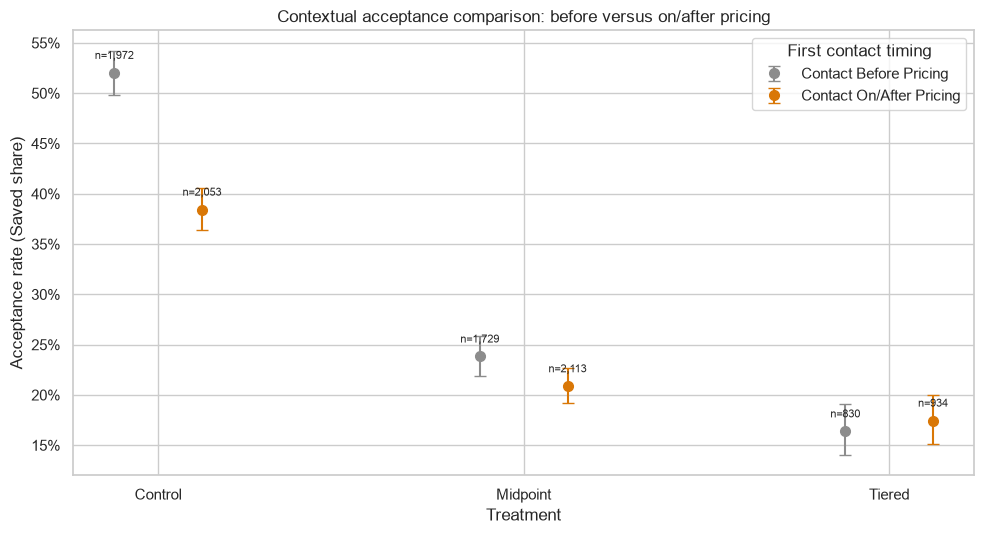

,Treatment,timing_context,users,accepted,median_gap_days,voluntary_stopped,acceptance_rate,ci_lower,ci_upper
0,Control,Contact Before Pricing,1972,1026,-27.000,946,0.520,0.498,0.542
1,Control,Contact On/After Pricing,2053,789,29.000,1264,0.384,0.364,0.406
2,Midpoint,Contact Before Pricing,1729,412,-27.000,1317,0.238,0.219,0.259
3,Midpoint,Contact On/After Pricing,2113,441,25.000,1672,0.209,0.192,0.227
4,Tiered,Contact Before Pricing,830,136,-27.000,694,0.164,0.140,0.191
5,Tiered,Contact On/After Pricing,934,163,26.500,771,0.175,0.152,0.200


In [6]:
mature_users = df.loc[mature].copy()
mature_users["timing_context"] = np.where(
    mature_users["gap_days"].lt(0),
    "Contact Before Pricing",
    "Contact On/After Pricing",
)
context_order = ["Contact Before Pricing", "Contact On/After Pricing"]
context_summary = summarize_acceptance(
    mature_users, ["Treatment", "timing_context"]
)
context_summary.to_csv(TABLE_DIR / "before_vs_on_after_acceptance.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 5.5))
base_x = np.arange(len(TREATMENT_ORDER), dtype=float)
offsets = [-0.12, 0.12]
context_colors = ["#8C8C8C", "#D97706"]
for timing, offset, color in zip(context_order, offsets, context_colors):
    plot_data = (
        context_summary.loc[context_summary["timing_context"].eq(timing)]
        .set_index("Treatment").reindex(TREATMENT_ORDER)
    )
    y = plot_data["acceptance_rate"].to_numpy()
    ax.errorbar(
        base_x + offset, y,
        yerr=[y - plot_data["ci_lower"], plot_data["ci_upper"] - y],
        fmt="o", color=color, capsize=4, markersize=7, label=timing,
    )
    for x_value, rate, users in zip(base_x + offset, y, plot_data["users"]):
        ax.annotate(f"n={int(users):,}", (x_value, rate), xytext=(0, 10),
                    textcoords="offset points", ha="center", fontsize=8)
ax.set_xticks(base_x, TREATMENT_ORDER)
ax.set_ylabel("Acceptance rate (Saved share)")
ax.set_xlabel("Treatment")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
ax.set_title("Contextual acceptance comparison: before versus on/after pricing")
ax.legend(title="First contact timing")
fig.tight_layout()
fig.savefig(CHART_DIR / "before_vs_on_after_acceptance.png", dpi=300, bbox_inches="tight")
plt.show()
display(context_summary)

## 5. Continuous association by Treatment

The point-biserial correlation is the ordinary correlation between the exact day gap and the binary Saved indicator. Bootstrap intervals describe its sampling uncertainty. Because a single correlation assumes an approximately linear probability relationship, the main visualization uses a restricted cubic spline logistic model with common business-readable knots at 0, 7, 30, 60, and 90 days.

In [7]:
def point_biserial_correlation(gap_days, accepted):
    gap_days = np.asarray(gap_days, dtype=float)
    accepted = np.asarray(accepted, dtype=float)
    if gap_days.std() == 0 or accepted.std() == 0:
        return np.nan
    return np.corrcoef(gap_days, accepted)[0, 1]


def bootstrap_correlation(data, iterations=1_000, random_state=31):
    x = data["gap_days"].to_numpy(dtype=float)
    y = data["accepted"].to_numpy(dtype=float)
    rng = np.random.default_rng(random_state)
    estimates = np.empty(iterations)
    for iteration in range(iterations):
        sample = rng.integers(0, len(data), len(data))
        estimates[iteration] = point_biserial_correlation(x[sample], y[sample])
    return np.nanquantile(estimates, [0.025, 0.975])


correlation_records = []
for treatment_index, treatment in enumerate(TREATMENT_ORDER):
    treatment_data = primary.loc[primary["Treatment"].eq(treatment)]
    lower, upper = bootstrap_correlation(
        treatment_data, BOOTSTRAP_ITERATIONS, random_state=31 + treatment_index
    )
    correlation_records.append(
        {
            "Treatment": treatment,
            "users": len(treatment_data),
            "point_biserial_correlation": point_biserial_correlation(
                treatment_data["gap_days"], treatment_data["accepted"]
            ),
            "ci_lower": lower,
            "ci_upper": upper,
        }
    )
correlation_summary = pd.DataFrame(correlation_records)
correlation_summary.to_csv(TABLE_DIR / "point_biserial_correlations.csv", index=False)
display(correlation_summary)

,Treatment,users,point_biserial_correlation,ci_lower,ci_upper
0,Control,2053,-0.184,-0.226,-0.145
1,Midpoint,2113,-0.105,-0.146,-0.061
2,Tiered,934,-0.025,-0.087,0.038


In [8]:
def expit(values):
    values = np.clip(np.asarray(values, dtype=float), -35, 35)
    return 1 / (1 + np.exp(-values))


def fit_logistic_irls(design, outcome, max_iterations=100, tolerance=1e-9):
    design = np.asarray(design, dtype=float)
    outcome = np.asarray(outcome, dtype=float)
    coefficients = np.zeros(design.shape[1])
    penalty = np.eye(design.shape[1]) * 1e-8
    penalty[0, 0] = 0
    for _ in range(max_iterations):
        probabilities = expit(design @ coefficients)
        weights = np.clip(probabilities * (1 - probabilities), 1e-8, None)
        information = design.T @ (weights[:, None] * design) + penalty
        score = design.T @ (outcome - probabilities) - penalty @ coefficients
        step = np.linalg.solve(information, score)
        coefficients = coefficients + step
        if np.max(np.abs(step)) < tolerance:
            break
    else:
        raise RuntimeError("Logistic model did not converge.")
    probabilities = expit(design @ coefficients)
    weights = np.clip(probabilities * (1 - probabilities), 1e-8, None)
    information = design.T @ (weights[:, None] * design) + penalty
    covariance = np.linalg.inv(information)
    log_likelihood = np.sum(
        outcome * np.log(np.clip(probabilities, 1e-12, 1))
        + (1 - outcome) * np.log(np.clip(1 - probabilities, 1e-12, 1))
    )
    return {"coefficients": coefficients, "covariance": covariance,
            "log_likelihood": log_likelihood}


def restricted_cubic_spline_basis(values, knots=SPLINE_KNOTS):
    values = np.asarray(values, dtype=float)
    knots = np.asarray(knots, dtype=float)
    scale = knots[-1] - knots[0]
    x = values / scale
    scaled_knots = knots / scale
    last = scaled_knots[-1]
    penultimate = scaled_knots[-2]
    denominator = last - penultimate
    columns = [x]
    for knot in scaled_knots[:-2]:
        term = (
            np.maximum(x - knot, 0) ** 3
            - np.maximum(x - penultimate, 0) ** 3 * (last - knot) / denominator
            + np.maximum(x - last, 0) ** 3 * (penultimate - knot) / denominator
        )
        columns.append(term)
    return np.column_stack(columns)


def spline_design(values):
    basis = restricted_cubic_spline_basis(values)
    return np.column_stack([np.ones(len(basis)), basis])


def predict_logistic(model, design):
    design = np.asarray(design, dtype=float)
    linear = design @ model["coefficients"]
    variance = np.einsum("ij,jk,ik->i", design, model["covariance"], design)
    standard_error = np.sqrt(np.clip(variance, 0, None))
    return expit(linear), expit(linear - 1.96 * standard_error), expit(linear + 1.96 * standard_error)


def chi_square_survival_even(statistic, degrees_of_freedom):
    if degrees_of_freedom % 2:
        raise ValueError("This compact implementation requires even degrees of freedom.")
    half_statistic = statistic / 2
    return math.exp(-half_statistic) * sum(
        half_statistic**term / math.factorial(term)
        for term in range(degrees_of_freedom // 2)
    )

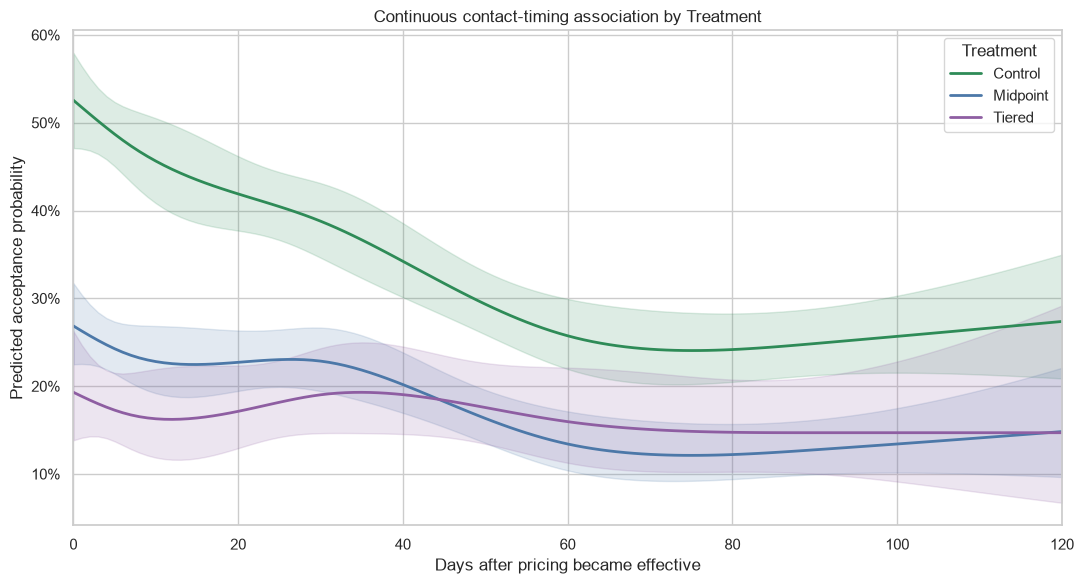

,Treatment,gap_days,predicted_acceptance,ci_lower,ci_upper
0,Control,0,0.526,0.471,0.579
1,Control,7,0.473,0.432,0.515
2,Control,14,0.439,0.389,0.490
3,Control,30,0.388,0.346,0.431
4,Control,60,0.257,0.220,0.299
5,Control,90,0.249,0.213,0.288
6,Midpoint,0,0.269,0.225,0.317
7,Midpoint,7,0.235,0.204,0.270
8,Midpoint,14,0.225,0.188,0.267
9,Midpoint,30,0.229,0.194,0.267


,Treatment,users,odds_ratio_per_7_days,ci_lower,ci_upper
0,Control,2053,0.919,0.900,0.938
1,Midpoint,2113,0.940,0.916,0.964
2,Tiered,934,0.984,0.946,1.025


In [9]:
prediction_grid = np.arange(0, 121, dtype=float)
curve_records = []
point_records = []
weekly_odds_records = []
models = {}

for treatment in TREATMENT_ORDER:
    treatment_data = primary.loc[primary["Treatment"].eq(treatment)]
    outcome = treatment_data["accepted"].to_numpy(dtype=float)
    model = fit_logistic_irls(spline_design(treatment_data["gap_days"]), outcome)
    models[treatment] = model
    predicted, lower, upper = predict_logistic(model, spline_design(prediction_grid))
    for day, estimate, low, high in zip(prediction_grid, predicted, lower, upper):
        curve_records.append(
            {"Treatment": treatment, "gap_days": day,
             "predicted_acceptance": estimate, "ci_lower": low, "ci_upper": high}
        )
    point_design = spline_design(np.asarray(PREDICTION_DAYS, dtype=float))
    point_estimate, point_lower, point_upper = predict_logistic(model, point_design)
    for day, estimate, low, high in zip(PREDICTION_DAYS, point_estimate, point_lower, point_upper):
        point_records.append(
            {"Treatment": treatment, "gap_days": day,
             "predicted_acceptance": estimate, "ci_lower": low, "ci_upper": high}
        )

    linear_design = np.column_stack(
        [np.ones(len(treatment_data)), treatment_data["gap_days"].to_numpy() / 7]
    )
    linear_model = fit_logistic_irls(linear_design, outcome)
    coefficient = linear_model["coefficients"][1]
    standard_error = np.sqrt(linear_model["covariance"][1, 1])
    weekly_odds_records.append(
        {
            "Treatment": treatment,
            "users": len(treatment_data),
            "odds_ratio_per_7_days": np.exp(coefficient),
            "ci_lower": np.exp(coefficient - 1.96 * standard_error),
            "ci_upper": np.exp(coefficient + 1.96 * standard_error),
        }
    )

curve_predictions = pd.DataFrame(curve_records)
prediction_points = pd.DataFrame(point_records)
weekly_odds = pd.DataFrame(weekly_odds_records)
curve_predictions.to_csv(TABLE_DIR / "spline_curve_predictions.csv", index=False)
prediction_points.to_csv(TABLE_DIR / "spline_selected_day_predictions.csv", index=False)
weekly_odds.to_csv(TABLE_DIR / "unadjusted_weekly_odds_ratios.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 6))
for treatment in TREATMENT_ORDER:
    plot_data = curve_predictions.loc[curve_predictions["Treatment"].eq(treatment)]
    color = TREATMENT_COLORS[treatment]
    ax.plot(plot_data["gap_days"], plot_data["predicted_acceptance"],
            color=color, linewidth=2, label=treatment)
    ax.fill_between(plot_data["gap_days"], plot_data["ci_lower"],
                    plot_data["ci_upper"], color=color, alpha=0.16)
ax.set_xlim(0, 120)
ax.set_xlabel("Days after pricing became effective")
ax.set_ylabel("Predicted acceptance probability")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
ax.set_title("Continuous contact-timing association by Treatment")
ax.legend(title="Treatment")
fig.tight_layout()
fig.savefig(CHART_DIR / "spline_acceptance_curves.png", dpi=300, bbox_inches="tight")
plt.show()
display(prediction_points, weekly_odds)

### Does the timing curve differ by Treatment?

The pooled additive model allows different Treatment intercepts but requires a common timing curve. The interaction model allows each Treatment to have its own curve. Their likelihood-ratio comparison tests the combined spline-by-Treatment interaction; it is more appropriate than comparing three correlation coefficients informally.

In [10]:
basis = restricted_cubic_spline_basis(primary["gap_days"])
midpoint = primary["Treatment"].eq("Midpoint").to_numpy(dtype=float)
tiered = primary["Treatment"].eq("Tiered").to_numpy(dtype=float)
treatment_indicators = np.column_stack([midpoint, tiered])
additive_design = np.column_stack([np.ones(len(primary)), basis, treatment_indicators])
interaction_design = np.column_stack(
    [additive_design, basis * midpoint[:, None], basis * tiered[:, None]]
)
outcome = primary["accepted"].to_numpy(dtype=float)
additive_model = fit_logistic_irls(additive_design, outcome)
interaction_model = fit_logistic_irls(interaction_design, outcome)
likelihood_ratio = 2 * (
    interaction_model["log_likelihood"] - additive_model["log_likelihood"]
)
interaction_df = interaction_design.shape[1] - additive_design.shape[1]
interaction_test = pd.DataFrame(
    [
        {
            "likelihood_ratio": likelihood_ratio,
            "degrees_of_freedom": interaction_df,
            "p_value": chi_square_survival_even(likelihood_ratio, interaction_df),
            "additive_log_likelihood": additive_model["log_likelihood"],
            "interaction_log_likelihood": interaction_model["log_likelihood"],
        }
    ]
)
interaction_test.to_csv(TABLE_DIR / "treatment_timing_interaction_test.csv", index=False)
display(interaction_test)

,likelihood_ratio,degrees_of_freedom,p_value,additive_log_likelihood,interaction_log_likelihood
0,15.029,8,0.059,"-2,829.729","-2,822.214"


## 6. Adjusted sensitivity analysis

Contact timing is not randomized. As a sensitivity check, the linear weekly timing association is adjusted separately within each Treatment for cohort, source risk tier, contact channel, pricing-effective month, and price-group order. The adjusted odds ratio remains descriptive; conditioning cannot remove unmeasured differences between early and late contacts.

In [11]:
def adjusted_weekly_odds_ratio(data):
    categorical = data[["cohort", "src_risk_tier", "contact_channels",
                        "pricing_effective_month"]].astype("string").fillna("Missing")
    indicators = pd.get_dummies(categorical, drop_first=True, dtype=float)
    price_order = data["pricegroup_order"].astype(float)
    price_order = price_order.fillna(price_order.median())
    price_scale = price_order.std()
    standardized_price = (price_order - price_order.mean()) / (price_scale if price_scale else 1)
    design = np.column_stack(
        [
            np.ones(len(data)),
            data["gap_days"].to_numpy(dtype=float) / 7,
            standardized_price.to_numpy(dtype=float),
            indicators.to_numpy(dtype=float),
        ]
    )
    model = fit_logistic_irls(design, data["accepted"])
    coefficient = model["coefficients"][1]
    standard_error = np.sqrt(model["covariance"][1, 1])
    return {
        "users": len(data),
        "adjustment_terms": design.shape[1] - 2,
        "odds_ratio_per_7_days": np.exp(coefficient),
        "ci_lower": np.exp(coefficient - 1.96 * standard_error),
        "ci_upper": np.exp(coefficient + 1.96 * standard_error),
    }


adjusted_records = []
for treatment in TREATMENT_ORDER:
    result = adjusted_weekly_odds_ratio(
        primary.loc[primary["Treatment"].eq(treatment)].copy()
    )
    adjusted_records.append({"Treatment": treatment, **result})
adjusted_weekly_odds = pd.DataFrame(adjusted_records)
adjusted_weekly_odds.to_csv(TABLE_DIR / "adjusted_weekly_odds_ratios.csv", index=False)

odds_comparison = weekly_odds.merge(
    adjusted_weekly_odds, on=["Treatment", "users"],
    suffixes=("_unadjusted", "_adjusted"),
)
odds_comparison.to_csv(TABLE_DIR / "weekly_odds_ratio_comparison.csv", index=False)
display(odds_comparison)

,Treatment,users,odds_ratio_per_7_days_unadjusted,ci_lower_unadjusted,ci_upper_unadjusted,adjustment_terms,odds_ratio_per_7_days_adjusted,ci_lower_adjusted,ci_upper_adjusted
0,Control,2053,0.919,0.900,0.938,12,0.924,0.903,0.945
1,Midpoint,2113,0.940,0.916,0.964,12,0.934,0.909,0.961
2,Tiered,934,0.984,0.946,1.025,10,0.985,0.942,1.030


## 7. Headline results table

This table places the main descriptive and modeled quantities side by side. Percentage-point differences compare rates or predicted probabilities; the odds ratio is the adjusted linear association per additional seven days.

In [12]:
context_rates = context_summary.pivot(
    index="Treatment", columns="timing_context", values="acceptance_rate"
)
selected_predictions = prediction_points.pivot(
    index="Treatment", columns="gap_days", values="predicted_acceptance"
)
headline_results = (
    correlation_summary[["Treatment", "users", "point_biserial_correlation",
                         "ci_lower", "ci_upper"]]
    .rename(columns={"ci_lower": "correlation_ci_lower",
                     "ci_upper": "correlation_ci_upper"})
    .merge(
        adjusted_weekly_odds[["Treatment", "odds_ratio_per_7_days",
                              "ci_lower", "ci_upper"]].rename(
            columns={"ci_lower": "adjusted_or_ci_lower",
                     "ci_upper": "adjusted_or_ci_upper"}
        ),
        on="Treatment",
    )
    .set_index("Treatment")
)
headline_results["acceptance_before_pricing"] = context_rates["Contact Before Pricing"]
headline_results["acceptance_on_after_pricing"] = context_rates["Contact On/After Pricing"]
headline_results["before_minus_on_after_pp"] = (
    headline_results["acceptance_before_pricing"]
    - headline_results["acceptance_on_after_pricing"]
) * 100
headline_results["predicted_acceptance_day_0"] = selected_predictions[0]
headline_results["predicted_acceptance_day_90"] = selected_predictions[90]
headline_results["predicted_day_90_minus_day_0_pp"] = (
    headline_results["predicted_acceptance_day_90"]
    - headline_results["predicted_acceptance_day_0"]
) * 100
headline_results = headline_results.reindex(TREATMENT_ORDER).reset_index()
headline_results.to_csv(TABLE_DIR / "headline_results.csv", index=False)
display(headline_results)

,Treatment,users,point_biserial_correlation,correlation_ci_lower,correlation_ci_upper,odds_ratio_per_7_days,adjusted_or_ci_lower,adjusted_or_ci_upper,acceptance_before_pricing,acceptance_on_after_pricing,before_minus_on_after_pp,predicted_acceptance_day_0,predicted_acceptance_day_90,predicted_day_90_minus_day_0_pp
0,Control,2053,-0.184,-0.226,-0.145,0.924,0.903,0.945,0.520,0.384,13.597,0.526,0.249,-27.711
1,Midpoint,2113,-0.105,-0.146,-0.061,0.934,0.909,0.961,0.238,0.209,2.958,0.269,0.128,-14.105
2,Tiered,934,-0.025,-0.087,0.038,0.985,0.942,1.030,0.164,0.175,-1.066,0.193,0.147,-4.603


## 8. Interpretation guide

- Use the weekly chart to describe observed acceptance rates in business-readable timing groups. Treat hollow, low-count points as unstable.
- Use the spline curves and selected-day predictions to describe the shape and magnitude of the continuous timing association within each Treatment.
- An odds ratio below 1 means that each additional seven days is associated with lower odds of being Saved; compare adjusted and unadjusted estimates for robustness.
- Use the pooled interaction test to determine whether the timing curve differs across Treatments, rather than comparing curve shapes visually alone.
- The Before Pricing comparison is contextual and should not be merged into the post-effective delay curve.
- None of these results identify a causal effect of delaying contact. Contact timing is post-assignment user behavior and may reflect urgency, channel choice, price sensitivity, or other unmeasured characteristics.